In [1]:
import numpy as np
import diversfun as fun
import matplotlib.pyplot as plt

fun.Colorblind(True)
fun.useTex(True)

### Spatiotemporal wavefront shaping

In [2]:
N = 240                                  # Size of the numerical example
RMax = 0.9                               # Radius of the numerical example
nFigs = 101                              # Number of temporal images
angle = 120                              # Angle of the aperture

Mask = fun.VortexMask(N, 0, Max=RMax)    # Mask of the example
Masks = fun.SectionMask(N, 101, angle, Max=RMax) # Example of the temporal sequence

# Loading experimental data
_FileName = f'Data/Exp_DMD.npy'
_theDict = np.load(_FileName, allow_pickle=True).item()

FP = _theDict['FullPupil']               # Round full pupil
Black = _theDict['Blacks']               # Black images to remove camera's noise
Imgs = _theDict[f'angle={angle}']        # Temporal sequence
Black = np.mean(Black, axis=0)           # Avaraging all images
FP = FP - Black                          # Removing camera's noise
Imgs = Imgs - Black                      # Removing camera's noise

# Loading analyzed data
_FileName = f'Data/Ana_DMD.npy'
_theDict = np.load(_FileName, allow_pickle=True).item()
Frqs = _theDict[f'Frqs_{angle}']        # Frequency domain
Amps = _theDict[f'Amps_{angle}']        # Amplitudes in the frequency domain
Harms = _theDict[f'Imgs_{angle}']       # Harmonics

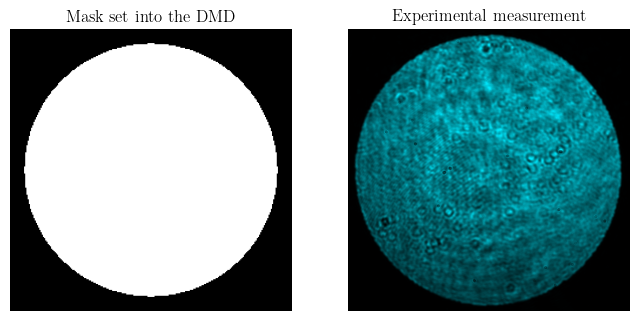

In [3]:
fig, ax = plt.subplots(1,2, figsize=(8, 4))
ax[0].imshow(np.abs(Mask), cmap='Greys_r')
ax[0].axis('off')
ax[0].set_title('Mask set into the DMD')

ax[1].imshow(FP, cmap=fun.ColorMaps('488nm'))
ax[1].axis('off')
ax[1].set_title('Experimental measurement')

plt.show()

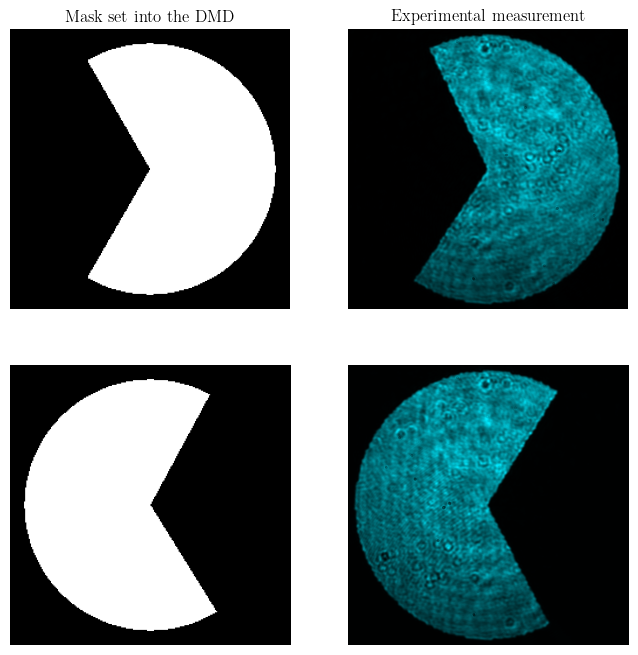

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8))
ax[0,0].imshow(np.abs(Masks[0]), cmap='Greys_r')
ax[0,0].axis('off')
ax[0,0].set_title('Mask set into the DMD')
ax[0,0].set_ylabel('Initial mask')

ax[1,0].imshow(np.abs(Masks[50]), cmap='Greys_r')
ax[1,0].axis('off')
ax[1,0].set_ylabel('Half sequence')

ax[0,1].imshow(Imgs[0], cmap=fun.ColorMaps('488nm'))
ax[0,1].axis('off')
ax[0,1].set_title('Experimental measurement')

ax[1,1].imshow(Imgs[50], cmap=fun.ColorMaps('488nm'))
ax[1,1].axis('off')

plt.show()

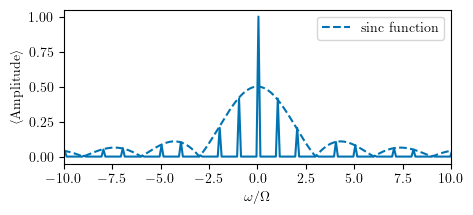

In [5]:
# Envelope
_frqs = np.linspace(-20, 20, 1001)
_Nangle = (2*np.pi)/(2*angle*np.pi/360)
_amps = np.abs(np.sinc(_frqs/_Nangle))/(_Nangle-1)

plt.figure(figsize=(5, 2))
plt.plot(Frqs, Amps/np.max(Amps), c='C0')
plt.plot(_frqs, _amps, ls='--', c='C0', label='sinc function')
plt.xlabel(r'$\omega/\Omega$')
plt.ylabel(r'$\langle$Amplitude$\rangle$')
plt.xlim(-10, 10)
plt.legend()
plt.show()

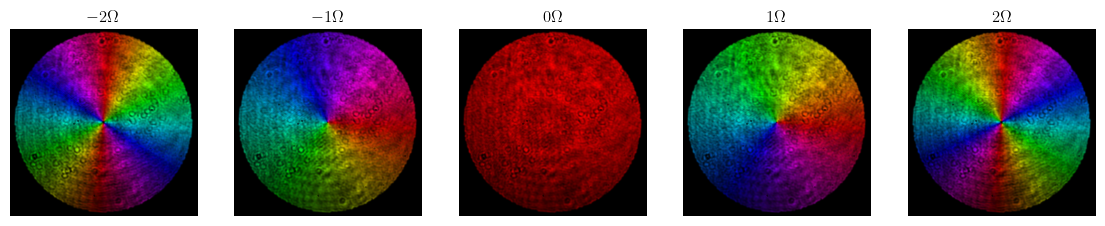

In [6]:
fig, ax = plt.subplots(1,5, figsize=(14, 4))
for i in range(5):
    ax[i].imshow(fun.Colorize(Harms[len(Harms)//2-2+i].T))
    ax[i].axis('off')
    ax[i].set_title(rf'${i-2}\Omega$')

plt.show()

## Aberrations

In [7]:
# Loading experimental data
_FileName = f'Data/Exp_Aberrations.npy'
_theDict = np.load(_FileName, allow_pickle=True).item()

FP = _theDict['FullPupil']               # Round full pupil
Black = _theDict['Blacks']               # Black images to remove camera's noise
Imgs = _theDict['Sequence']              # Temporal sequence
Black = np.mean(Black, axis=0)           # Avaraging all images
Imgs = Imgs - Black                      # Removing camera's noise

# Loading analyzed data
_FileName = f'Data/Ana_Aberrations.npy'
_theDict = np.load(_FileName, allow_pickle=True).item()

FPc = _theDict['FullPupil']              # Round full pupil
Harms = _theDict['Harms']                # Harmonics
Diffuser = _theDict['Diffuser']           # Diffuser
Loss = _theDict['TotLoss']                # Loss
Time = _theDict['ElapsedTime']            # Elapsed Time
Scale = _theDict['Scale']                 # Scale

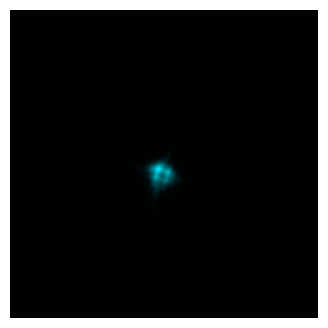

In [8]:
plt.figure(figsize = (4, 4))
plt.imshow(FP, cmap=fun.ColorMaps('488nm'))
plt.axis('off')
plt.show()

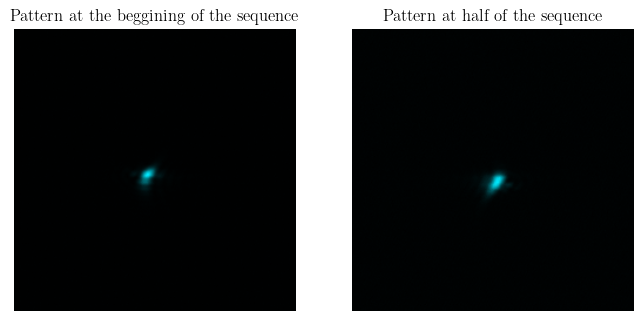

In [9]:
fig, ax = plt.subplots(1,2, figsize=(8, 4))
ax[0].imshow(Imgs[0], cmap=fun.ColorMaps('488nm'))
ax[0].axis('off')
ax[0].set_title('Pattern at the beggining of the sequence')

ax[1].imshow(Imgs[50], cmap=fun.ColorMaps('488nm'))
ax[1].axis('off')
ax[1].set_title('Pattern at half of the sequence')

plt.show()

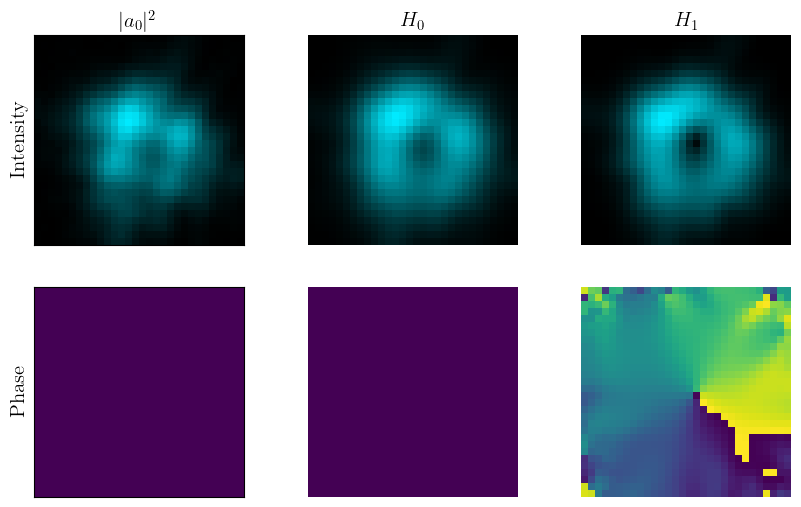

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(10, 6))

ax[0,0].set_title(r'$|a_0|^2$', fontsize=15)
ax[0,0].set_ylabel('Intensity', fontsize=15)
ax[0,0].imshow(FPc, cmap=fun.ColorMaps('488nm'))
ax[1,0].set_ylabel('Phase', fontsize=15)
ax[1,0].imshow(np.angle(FPc))
for i in range(2):
    ax[i,0].set_xticks([])
    ax[i,0].set_yticks([])

ax[0,1].set_title(r'$H_0$', fontsize=15)
ax[0,1].imshow(np.abs(Harms[0]), cmap=fun.ColorMaps('488nm'))
ax[0,1].axis('off')
ax[1,1].imshow(np.angle(Harms[0]))
ax[1,1].axis('off')

ax[0,2].set_title(r'$H_1$', fontsize=15)
ax[0,2].imshow(np.abs(Harms[1]), cmap=fun.ColorMaps('488nm'))
ax[0,2].axis('off')
ax[1,2].imshow(np.angle(Harms[1]))
ax[1,2].axis('off')

plt.show()

### Reconstruction

In [11]:
N = 30                                     # Number of pixels
RMax = 1                                   # Radius of the support
NPad = 10                                  # Padding of the support

cp1, cm1 = fun.GetFourierConstants(np.pi)  # Computing the Fourier coeffitiens
VMasks = fun.VortexMask(N, 1, Max=RMax)    # Helical mask

# Modulating the diffuser by the helical mask
Specklesp = []
for _mask in VMasks:
    _out = fun.GetFarField(_mask*Diffuser, NPad, Scale=Scale)
    Specklesp.append(_out.astype(complex))

# Computing the harmonics of the intensity by the spiral phase diversity
H0p = np.abs(cm1*Specklesp[0])**2 + np.abs(Specklesp[1])**2 + np.abs(cp1*Specklesp[2])**2
H1p =  cm1*Specklesp[1]*Specklesp[0].conj() + cp1*Specklesp[2]*Specklesp[1].conj()

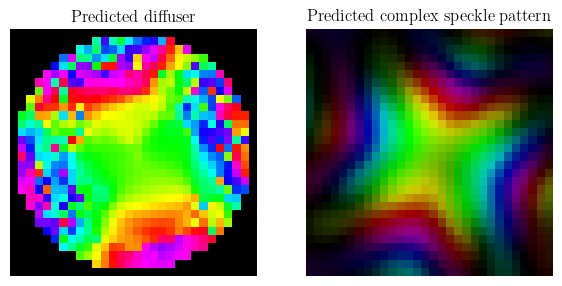

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(7, 4))
ax[0].imshow(fun.Colorize(Diffuser*VMasks[1].T))
ax[0].axis('off')
ax[0].set_title('Predicted diffuser')

ax[1].imshow(fun.Colorize(Specklesp[1].T))
ax[1].axis('off')
ax[1].set_title('Predicted complex speckle pattern')

plt.show()

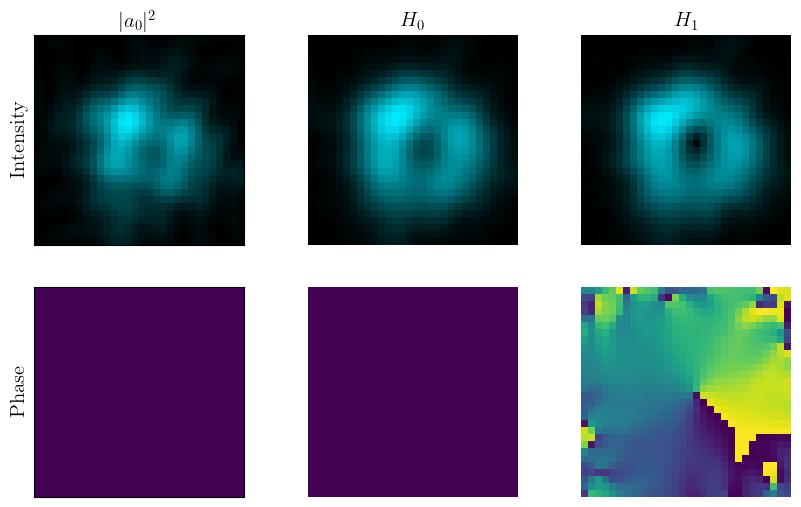

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(10, 6))

ax[0,0].set_title(r'$|a_0|^2$', fontsize=15)
ax[0,0].set_ylabel('Intensity', fontsize=15)
ax[0,0].imshow(np.abs(Specklesp[1])**2, cmap=fun.ColorMaps('488nm'))
ax[1,0].set_ylabel('Phase', fontsize=15)
ax[1,0].imshow(np.angle(np.abs(Specklesp[1])**2))
for i in range(2):
    ax[i,0].set_xticks([])
    ax[i,0].set_yticks([])

ax[0,1].set_title(r'$H_0$', fontsize=15)
ax[0,1].imshow(np.abs(H0p), cmap=fun.ColorMaps('488nm'))
ax[0,1].axis('off')
ax[1,1].imshow(np.angle(H0p))
ax[1,1].axis('off')

ax[0,2].set_title(r'$H_1$', fontsize=15)
ax[0,2].imshow(np.abs(H1p), cmap=fun.ColorMaps('488nm'))
ax[0,2].axis('off')
ax[1,2].imshow(np.angle(H1p))
ax[1,2].axis('off')

plt.show()

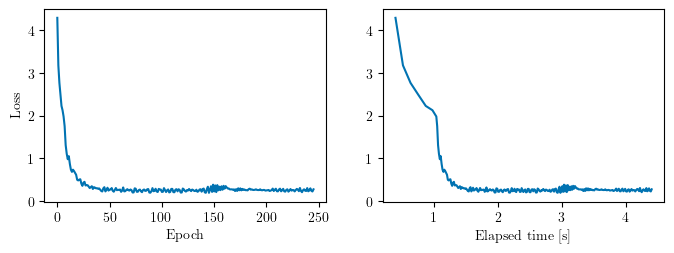

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(8, 2.5))
ax[0].plot(Loss)
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')

ax[1].plot(Time, Loss)
ax[1].set_xlabel('Elapsed time [s]')
plt.show()

In [15]:
print(rf'Correlation coefficient a_0^2: {np.corrcoef(FPc.ravel(), (np.abs(Specklesp[1])**2).ravel())[0,1]}')
print(rf'Correlation coefficient H_0: {np.corrcoef(Harms[0].ravel(), H0p.ravel())[0,1]}')
print(rf'Correlation coefficient H_1: {np.corrcoef(Harms[1].ravel(), H1p.ravel())[0,1]}')

Correlation coefficient a_0^2: 0.9962048079674871
Correlation coefficient H_0: (0.9977417999728606+0j)
Correlation coefficient H_1: (0.9988727467490804+0.0023348343101164347j)


### Focusing

In [16]:
DMDSize = 300                             # Pixels used in the DMD
GratingP = 8                              # Pixels of the grating
GratingA = np.pi/13                       # Angle of the grating

# Computing the Lee Hologram
Diffuser = Diffuser*fun.VortexMask(N, 0, Max=RMax)
Holo = np.repeat(np.repeat(Diffuser, DMDSize//N, axis=0), DMDSize//N,  axis=1)
N = len(Holo)
Holo = fun.LeeMask(Holo, GratingP, (N//2, N//2), GratingA, 8)

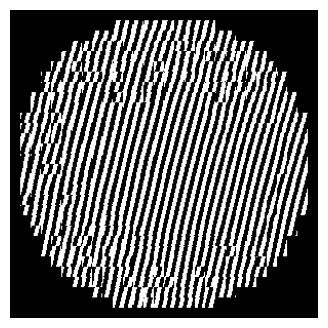

In [17]:
plt.figure(figsize=(4,4))
plt.imshow(Holo, cmap='Greys_r')
plt.axis('off')
plt.show()

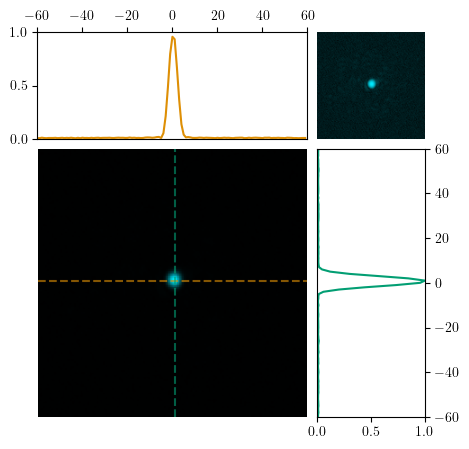

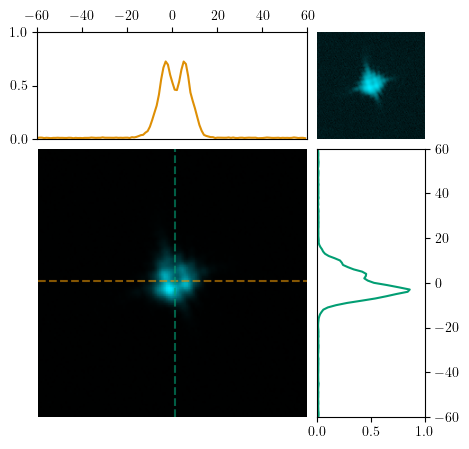

In [19]:
# Loading experimental image
_FileName = f'Data/Exp_Aberrations_Focusing.npy'
Foc = np.load(_FileName)

fun.Profiles(fun.CropCenter(Foc[15:, :-5], 120), CMap=fun.ColorMaps('488nm'))

fun.Profiles(fun.CropCenter(FP[15:, :-5], 120), CMap=fun.ColorMaps('488nm'))

## Holographic Diffuser 1°

In [21]:
# Loading experimental data
_FileName = f'Data/Exp_Diffuser_1.npy'
_theDict = np.load(_FileName, allow_pickle=True).item()

FP = _theDict['FullPupil']               # Round full pupil
FT = _theDict['FourierT']               # Round full pupil
Black = _theDict['Blacks']               # Black images to remove camera's noise
Imgs = _theDict['Sequence']              # Temporal sequence
Black = np.mean(Black, axis=0)           # Avaraging all images
Imgs = Imgs - Black                      # Removing camera's noise


# Loading analyzed data
_FileName = f'Data/Ana_Diffuser_1.npy'
_theDict = np.load(_FileName, allow_pickle=True).item()

FPc = _theDict['FullPupil']              # Round full pupil
Harms = _theDict['Harms']                # Harmonics
Diffuser = _theDict['Diffuser']           # Diffuser
Loss = _theDict['TotLoss']                # Loss
Time = _theDict['ElapsedTime']            # Elapsed Time
Scale = _theDict['Scale']                 # Scale

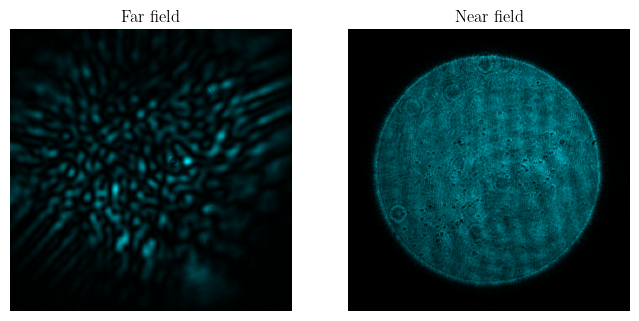

In [22]:
fig, ax = plt.subplots(1,2, figsize=(8, 4))
ax[0].imshow(FP, cmap=fun.ColorMaps('488nm'))
ax[0].axis('off')
ax[0].set_title('Far field')

ax[1].imshow(FT, cmap=fun.ColorMaps('488nm'))
ax[1].axis('off')
ax[1].set_title('Near field')

plt.show()

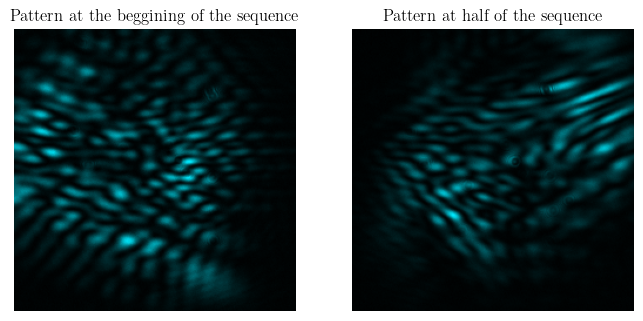

In [23]:
fig, ax = plt.subplots(1,2, figsize=(8, 4))
ax[0].imshow(Imgs[0], cmap=fun.ColorMaps('488nm'))
ax[0].axis('off')
ax[0].set_title('Pattern at the beggining of the sequence')

ax[1].imshow(Imgs[50], cmap=fun.ColorMaps('488nm'))
ax[1].axis('off')
ax[1].set_title('Pattern at half of the sequence')

plt.show()

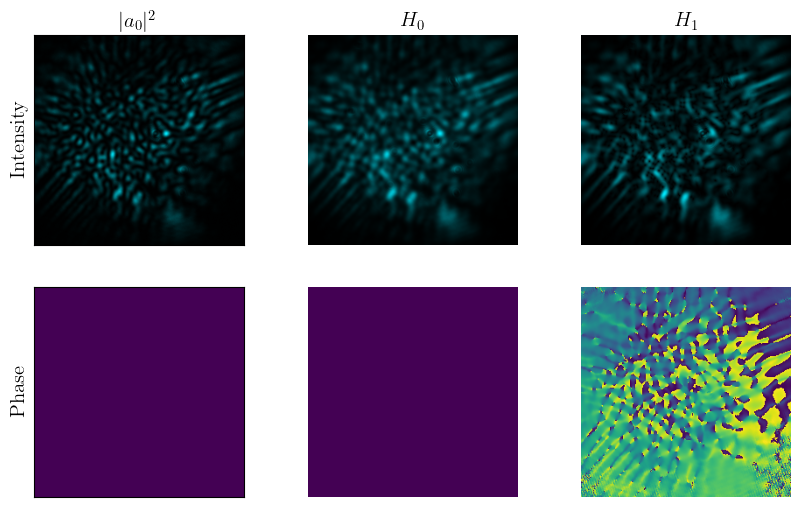

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(10, 6))

ax[0,0].set_title(r'$|a_0|^2$', fontsize=15)
ax[0,0].set_ylabel('Intensity', fontsize=15)
ax[0,0].imshow(FPc, cmap=fun.ColorMaps('488nm'))
ax[1,0].set_ylabel('Phase', fontsize=15)
ax[1,0].imshow(np.angle(FPc))
for i in range(2):
    ax[i,0].set_xticks([])
    ax[i,0].set_yticks([])

ax[0,1].set_title(r'$H_0$', fontsize=15)
ax[0,1].imshow(np.abs(Harms[0]), cmap=fun.ColorMaps('488nm'))
ax[0,1].axis('off')
ax[1,1].imshow(np.angle(Harms[0]))
ax[1,1].axis('off')

ax[0,2].set_title(r'$H_1$', fontsize=15)
ax[0,2].imshow(np.abs(Harms[1]), cmap=fun.ColorMaps('488nm'))
ax[0,2].axis('off')
ax[1,2].imshow(np.angle(Harms[1]))
ax[1,2].axis('off')

plt.show()

### Reconstruction

In [25]:
N = 180                                    # Number of pixels of the diffuser
ISize = 240                                # Number of pixels of the image
RMax = 1                                   # Radius of the support
NPad = 5                                   # Padding of the support

cp1, cm1 = fun.GetFourierConstants(np.pi)  # Computing the Fourier coeffitiens
VMasks = fun.VortexMask(N, 1, Max=RMax)    # Helical mask

# Modulating the diffuser by the helical mask
Specklesp = []
for _mask in VMasks:
    _out = fun.GetFarField(_mask*Diffuser, NPad, WinSize=ISize, Scale=Scale)
    Specklesp.append(_out.astype(complex))

# Computing the harmonics of the intensity by the spiral phase diversity
H0p = np.abs(cm1*Specklesp[0])**2 + np.abs(Specklesp[1])**2 + np.abs(cp1*Specklesp[2])**2
H1p =  cm1*Specklesp[1]*Specklesp[0].conj() + cp1*Specklesp[2]*Specklesp[1].conj()

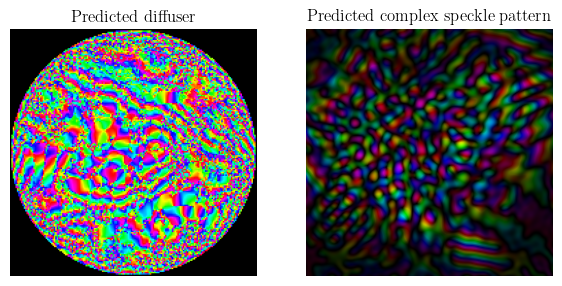

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(7, 4))
ax[0].imshow(fun.Colorize(Diffuser*VMasks[1].T))
ax[0].axis('off')
ax[0].set_title('Predicted diffuser')

ax[1].imshow(fun.Colorize(Specklesp[1].T))
ax[1].axis('off')
ax[1].set_title('Predicted complex speckle pattern')

plt.show()

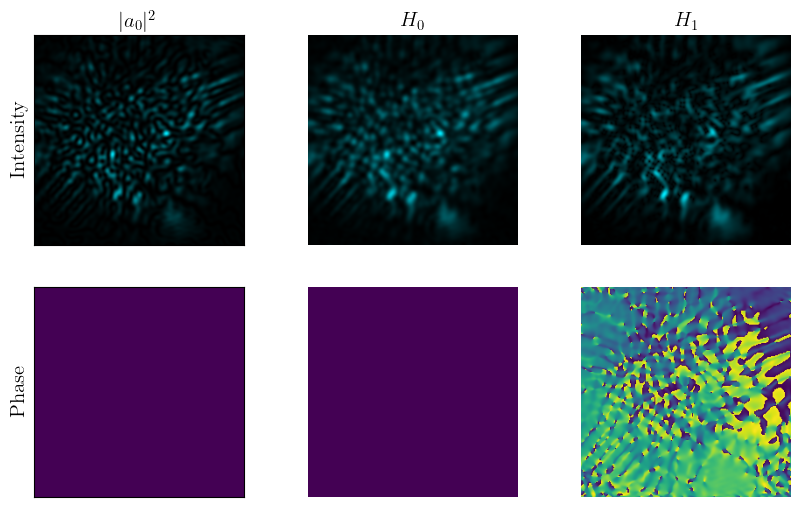

In [27]:
fig, ax = plt.subplots(2, 3, figsize=(10, 6))

ax[0,0].set_title(r'$|a_0|^2$', fontsize=15)
ax[0,0].set_ylabel('Intensity', fontsize=15)
ax[0,0].imshow(np.abs(Specklesp[1])**2, cmap=fun.ColorMaps('488nm'))
ax[1,0].set_ylabel('Phase', fontsize=15)
ax[1,0].imshow(np.angle(np.abs(Specklesp[1])**2))
for i in range(2):
    ax[i,0].set_xticks([])
    ax[i,0].set_yticks([])

ax[0,1].set_title(r'$H_0$', fontsize=15)
ax[0,1].imshow(np.abs(H0p), cmap=fun.ColorMaps('488nm'))
ax[0,1].axis('off')
ax[1,1].imshow(np.angle(H0p))
ax[1,1].axis('off')

ax[0,2].set_title(r'$H_1$', fontsize=15)
ax[0,2].imshow(np.abs(H1p), cmap=fun.ColorMaps('488nm'))
ax[0,2].axis('off')
ax[1,2].imshow(np.angle(H1p))
ax[1,2].axis('off')

plt.show()

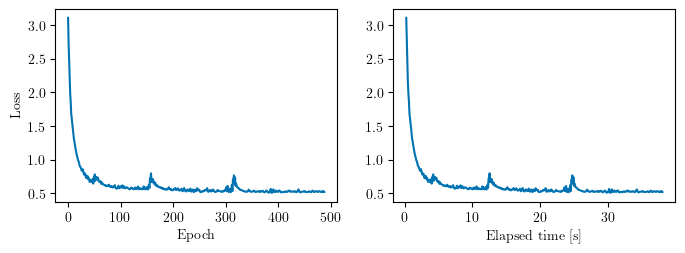

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(8, 2.5))
ax[0].plot(Loss)
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')

ax[1].plot(Time, Loss)
ax[1].set_xlabel('Elapsed time [s]')
plt.show()

In [29]:
print(rf'Correlation coefficient a_0^2: {np.corrcoef(FPc.ravel(), (np.abs(Specklesp[1])**2).ravel())[0,1]}')
print(rf'Correlation coefficient H_0: {np.corrcoef(Harms[0].ravel(), H0p.ravel())[0,1]}')
print(rf'Correlation coefficient H_1: {np.corrcoef(Harms[1].ravel(), H1p.ravel())[0,1]}')

Correlation coefficient a_0^2: 0.9891834457580124
Correlation coefficient H_0: (0.9916369931275417+0j)
Correlation coefficient H_1: (0.9903750140266829-0.002086765552001481j)


### Focusing

In [30]:
phase = -np.pi                           # Phase value to select
dphase = np.pi/26                        # Size of the phase window
rad = 40                                 # k-radius for phase ramp
phas = np.linspace(0, 2*np.pi, 17)[:-1]  # k-phases to explore

# Computing the binary mask
BinMask = fun.SelectPhase(Diffuser, phase, dphase)
BinMask = BinMask*np.abs(fun.VortexMask(N, 0, Max=RMax))

# Loading central focusing
_FileName = f'Data/Exp_Diffuser_1_Focusing.npy'
Foc = np.load(_FileName)

# Loading focusing with ramp
_FileName = f'Data/Exp_Diffuser_1_Focusing_Ramp.npy'
Focs = np.load(_FileName)

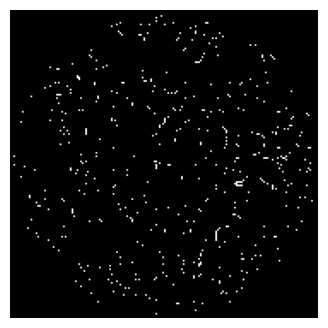

In [31]:
plt.figure(figsize=(4, 4))
plt.imshow(BinMask, cmap='Greys_r')
plt.axis('off')
plt.show()

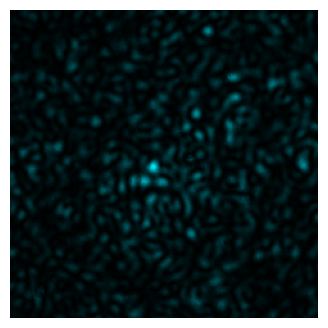

In [32]:
plt.figure(figsize=(4, 4))
plt.imshow(Foc, cmap=fun.ColorMaps('488nm'))
plt.axis('off')
plt.show()

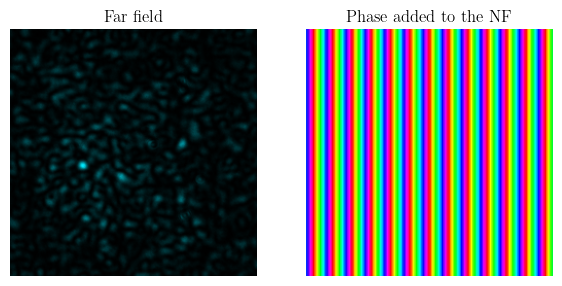

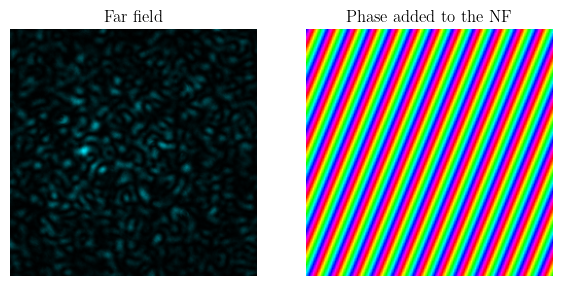

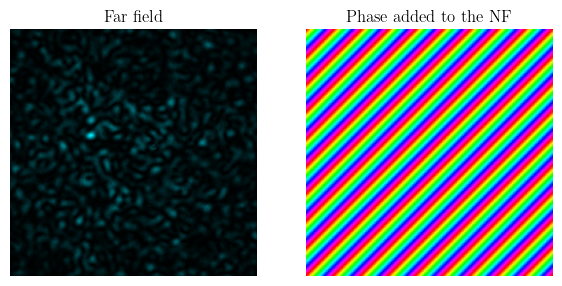

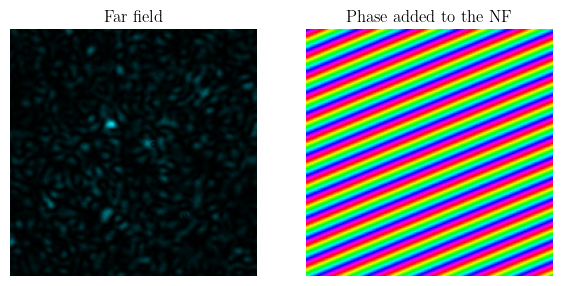

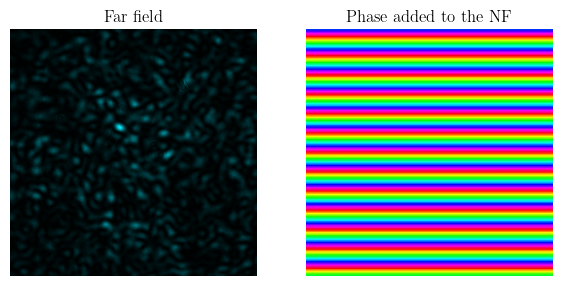

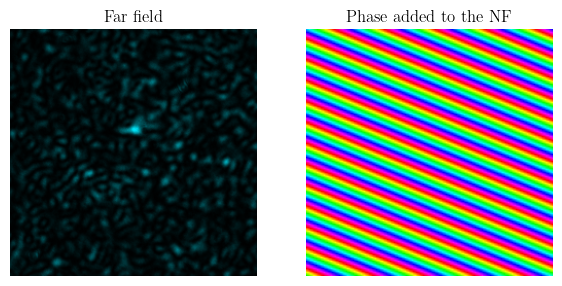

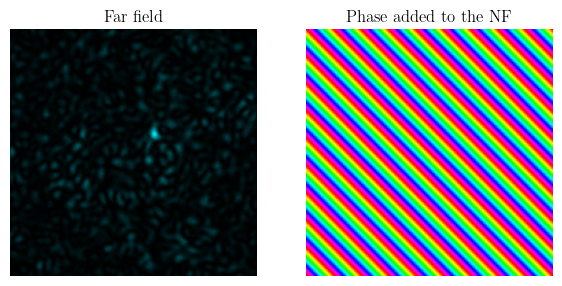

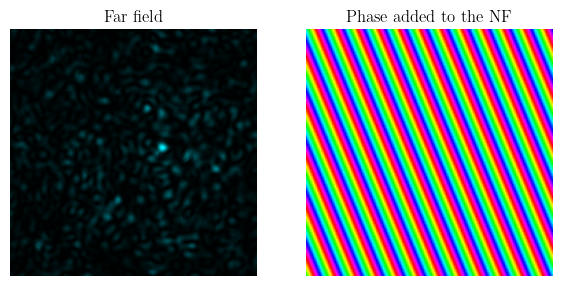

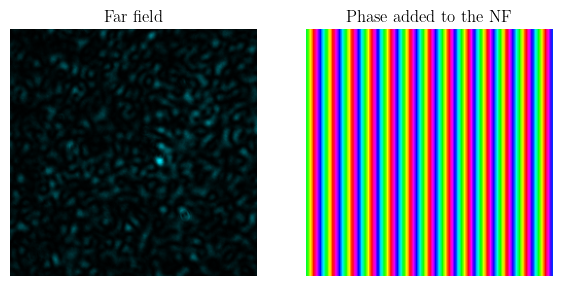

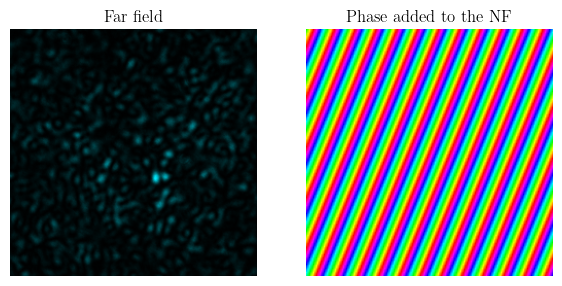

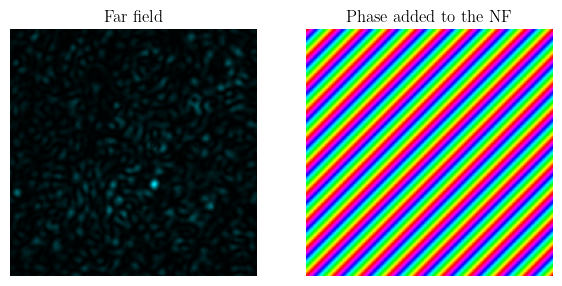

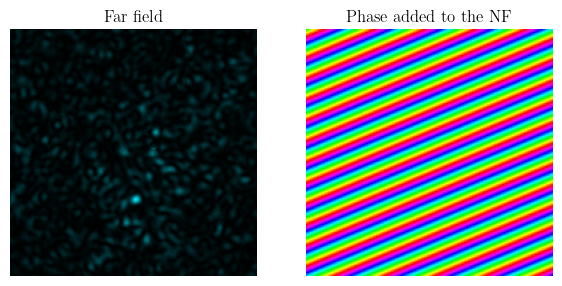

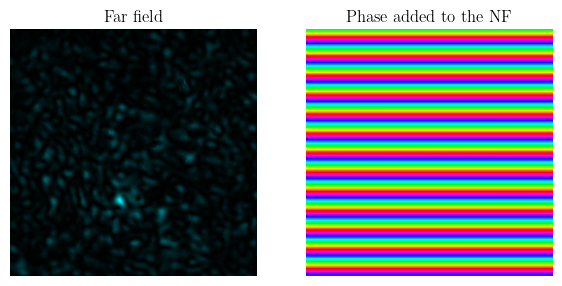

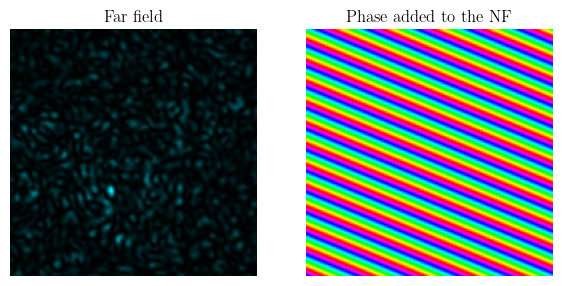

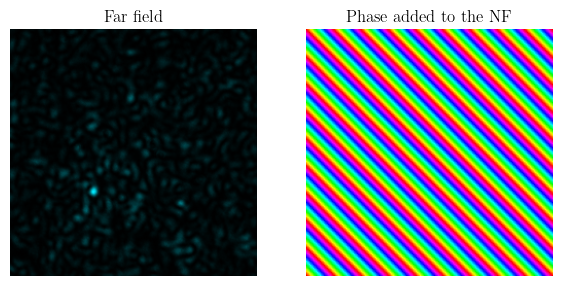

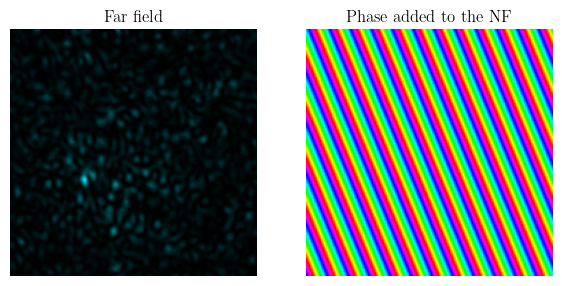

In [33]:
for i,_foc in enumerate(Focs):
    kx = rad*np.cos(phas[i])
    ky = rad*np.sin(phas[i])
    Ramp = fun.PhaseRampMask(N, kx, ky)

    fig, ax = plt.subplots(1, 2, figsize=(7, 4))
    ax[0].imshow(_foc, cmap=fun.ColorMaps('488nm'))
    ax[0].axis('off')
    ax[0].set_title('Far field')
    
    ax[1].imshow(fun.Colorize(Ramp.T))
    ax[1].axis('off')
    ax[1].set_title('Phase added to the NF')
    
    plt.show()

## Holographic Diffuser 5°

In [34]:
# Loading experimental data
_FileName = f'Data/Exp_Diffuser_5.npy'
_theDict = np.load(_FileName, allow_pickle=True).item()

FP = _theDict['FullPupil']               # Round full pupil
FT = _theDict['FourierT']               # Round full pupil
Black = _theDict['Blacks']               # Black images to remove camera's noise
Imgs = _theDict['Sequence']              # Temporal sequence
Black = np.mean(Black, axis=0)           # Avaraging all images
Imgs = Imgs - Black                      # Removing camera's noise


# Loading analyzed data
_FileName = f'Data/Ana_Diffuser_5.npy'
_theDict = np.load(_FileName, allow_pickle=True).item()

FPc = _theDict['FullPupil']              # Round full pupil
Harms = _theDict['Harms']                # Harmonics
Diffuser = _theDict['Diffuser']           # Diffuser
Loss = _theDict['TotLoss']                # Loss
Time = _theDict['ElapsedTime']            # Elapsed Time
Scale = _theDict['Scale']                 # Scale

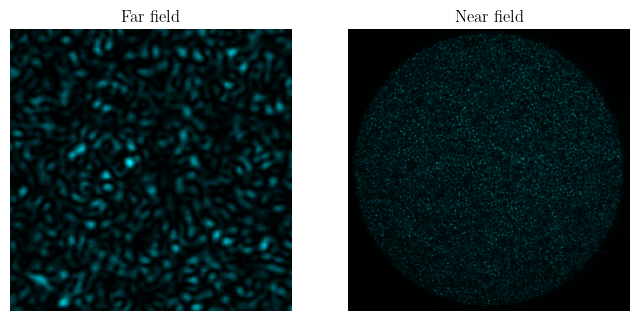

In [35]:
fig, ax = plt.subplots(1,2, figsize=(8, 4))
ax[0].imshow(FP, cmap=fun.ColorMaps('488nm'))
ax[0].axis('off')
ax[0].set_title('Far field')

ax[1].imshow(FT, cmap=fun.ColorMaps('488nm'))
ax[1].axis('off')
ax[1].set_title('Near field')

plt.show()

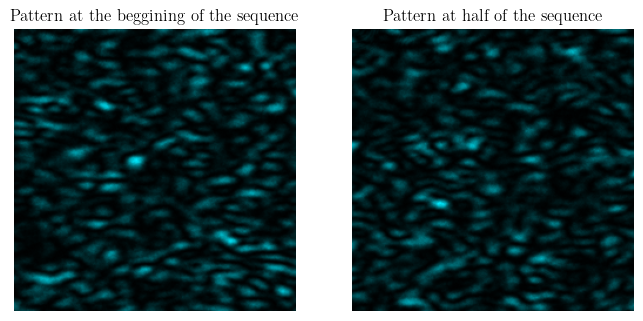

In [36]:
fig, ax = plt.subplots(1,2, figsize=(8, 4))
ax[0].imshow(Imgs[0], cmap=fun.ColorMaps('488nm'))
ax[0].axis('off')
ax[0].set_title('Pattern at the beggining of the sequence')

ax[1].imshow(Imgs[50], cmap=fun.ColorMaps('488nm'))
ax[1].axis('off')
ax[1].set_title('Pattern at half of the sequence')

plt.show()

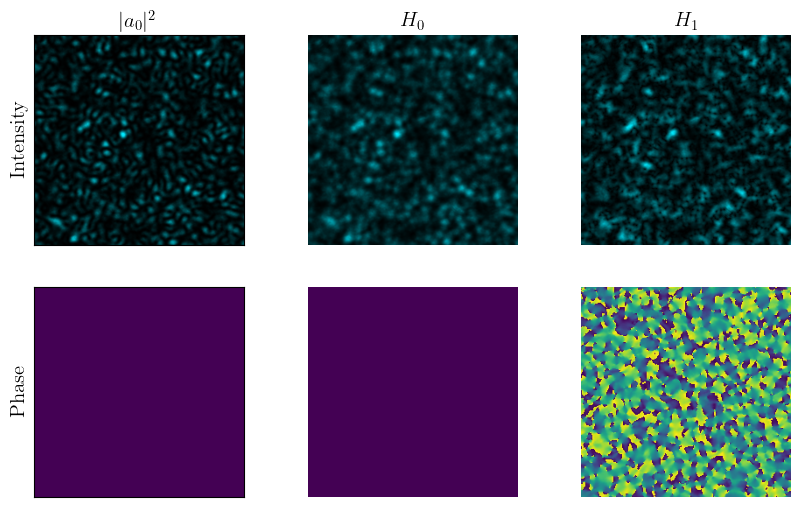

In [37]:
fig, ax = plt.subplots(2, 3, figsize=(10, 6))

ax[0,0].set_title(r'$|a_0|^2$', fontsize=15)
ax[0,0].set_ylabel('Intensity', fontsize=15)
ax[0,0].imshow(FPc, cmap=fun.ColorMaps('488nm'))
ax[1,0].set_ylabel('Phase', fontsize=15)
ax[1,0].imshow(np.angle(FPc))
for i in range(2):
    ax[i,0].set_xticks([])
    ax[i,0].set_yticks([])

ax[0,1].set_title(r'$H_0$', fontsize=15)
ax[0,1].imshow(np.abs(Harms[0]), cmap=fun.ColorMaps('488nm'))
ax[0,1].axis('off')
ax[1,1].imshow(np.angle(Harms[0]))
ax[1,1].axis('off')

ax[0,2].set_title(r'$H_1$', fontsize=15)
ax[0,2].imshow(np.abs(Harms[1]), cmap=fun.ColorMaps('488nm'))
ax[0,2].axis('off')
ax[1,2].imshow(np.angle(Harms[1]))
ax[1,2].axis('off')

plt.show()

### Reconstruction

In [38]:
N = 180                                    # Number of pixels of the diffuser
ISize = 240                                # Number of pixels of the image
RMax = 1                                   # Radius of the support
NPad = 5                                   # Padding of the support

cp1, cm1 = fun.GetFourierConstants(np.pi)  # Computing the Fourier coeffitiens
VMasks = fun.VortexMask(N, 1, Max=RMax)    # Helical mask

# Modulating the diffuser by the helical mask
Specklesp = []
for _mask in VMasks:
    _out = fun.GetFarField(_mask*Diffuser, NPad, WinSize=ISize, Scale=Scale)
    Specklesp.append(_out.astype(complex))

# Computing the harmonics of the intensity by the spiral phase diversity
H0p = np.abs(cm1*Specklesp[0])**2 + np.abs(Specklesp[1])**2 + np.abs(cp1*Specklesp[2])**2
H1p =  cm1*Specklesp[1]*Specklesp[0].conj() + cp1*Specklesp[2]*Specklesp[1].conj()

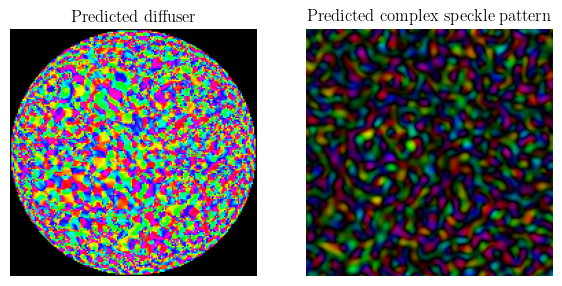

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(7, 4))
ax[0].imshow(fun.Colorize(Diffuser*VMasks[1].T))
ax[0].axis('off')
ax[0].set_title('Predicted diffuser')

ax[1].imshow(fun.Colorize(Specklesp[1].T))
ax[1].axis('off')
ax[1].set_title('Predicted complex speckle pattern')

plt.show()

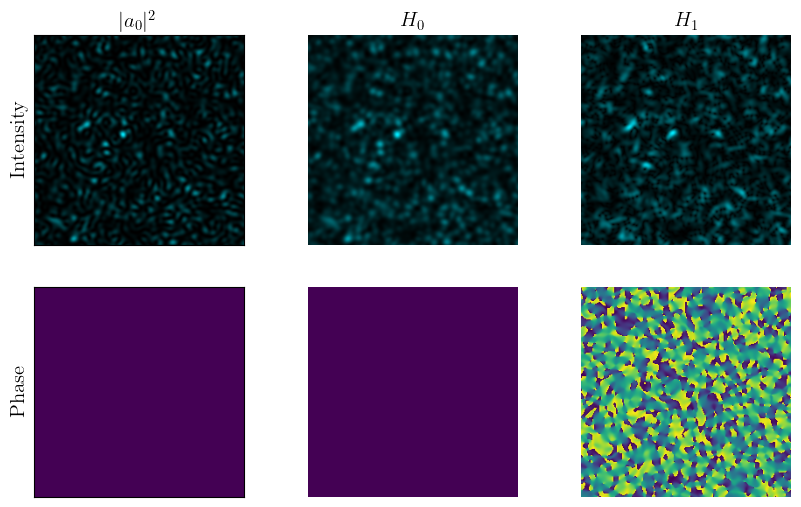

In [40]:
fig, ax = plt.subplots(2, 3, figsize=(10, 6))

ax[0,0].set_title(r'$|a_0|^2$', fontsize=15)
ax[0,0].set_ylabel('Intensity', fontsize=15)
ax[0,0].imshow(np.abs(Specklesp[1])**2, cmap=fun.ColorMaps('488nm'))
ax[1,0].set_ylabel('Phase', fontsize=15)
ax[1,0].imshow(np.angle(np.abs(Specklesp[1])**2))
for i in range(2):
    ax[i,0].set_xticks([])
    ax[i,0].set_yticks([])

ax[0,1].set_title(r'$H_0$', fontsize=15)
ax[0,1].imshow(np.abs(H0p), cmap=fun.ColorMaps('488nm'))
ax[0,1].axis('off')
ax[1,1].imshow(np.angle(H0p))
ax[1,1].axis('off')

ax[0,2].set_title(r'$H_1$', fontsize=15)
ax[0,2].imshow(np.abs(H1p), cmap=fun.ColorMaps('488nm'))
ax[0,2].axis('off')
ax[1,2].imshow(np.angle(H1p))
ax[1,2].axis('off')

plt.show()

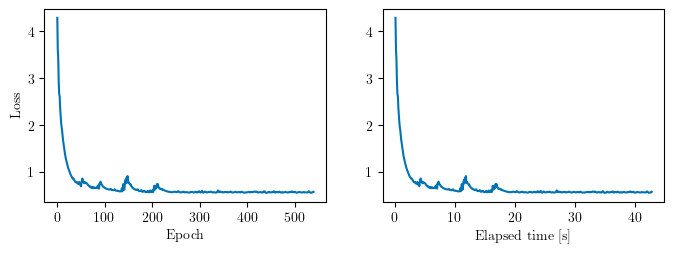

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(8, 2.5))
ax[0].plot(Loss)
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')

ax[1].plot(Time, Loss)
ax[1].set_xlabel('Elapsed time [s]')
plt.show()

In [42]:
print(rf'Correlation coefficient a_0^2: {np.corrcoef(FPc.ravel(), (np.abs(Specklesp[1])**2).ravel())[0,1]}')
print(rf'Correlation coefficient H_0: {np.corrcoef(Harms[0].ravel(), H0p.ravel())[0,1]}')
print(rf'Correlation coefficient H_1: {np.corrcoef(Harms[1].ravel(), H1p.ravel())[0,1]}')

Correlation coefficient a_0^2: 0.9815607799742466
Correlation coefficient H_0: (0.980580123101091+0j)
Correlation coefficient H_1: (0.9805231303722307-0.0011539940388776621j)
